# Loading data using Pandas

In [1]:
#importing pandas library
import pandas as pd

In [3]:
#loading data
titanic = pd.read_csv(r"C:\Users\pooja\Downloads\titanic.csv")

In [4]:
titanic.describe() 

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [13]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    int64  
 15  Family_Size  891 non-null    int64  
dtypes: bool(1), float64(2), int64(6), object(7)
memory usage: 105.4+ KB


# Printing data head

In [7]:
# View first five rows of the dataset
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


# Checking the NULL values  

In [8]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

# Graphical Analysis 

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

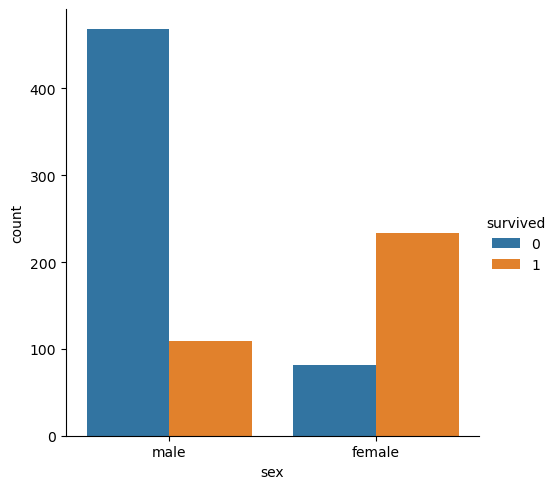

In [5]:
# Countplot
sns.catplot(x ="sex", hue ="survived",kind ="count", data = titanic)

# pclass (Ordinal Feature) vs survived  

In [21]:
# Group the dataset by Pclass and Survived and then unstack them
group = titanic.groupby(['pclass', 'survived'])
pclass_survived = group.size().unstack()

<Axes: xlabel='survived', ylabel='pclass'>

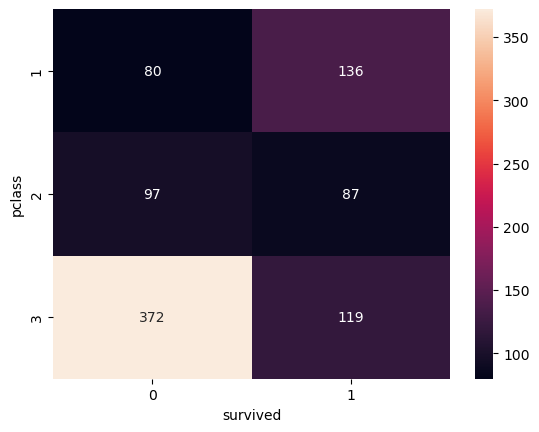

In [22]:
# Heatmap - Color encoded 2D representation of data.
sns.heatmap(pclass_survived, annot = True, fmt ="d")

# Age (Continuous Feature) vs Survived  

<Axes: xlabel='sex', ylabel='age'>

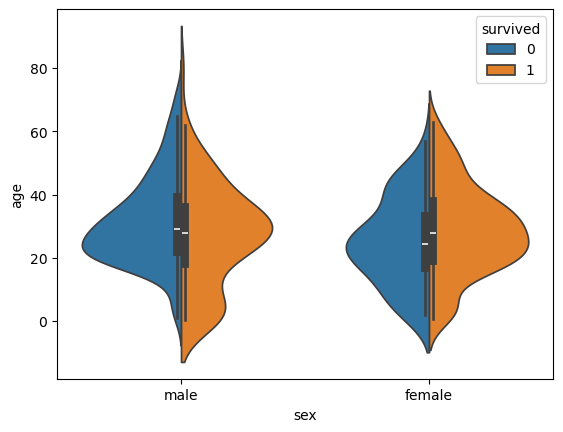

In [23]:
# Violinplot Displays distribution of data 
# across all levels of a category.
sns.violinplot(x ="sex", y ="age", hue ="survived", 
data = titanic, split = True)

# Violinplot for Family_Size (Count Feature) and Family Size.

<Axes: xlabel='Family_Size', ylabel='survived'>

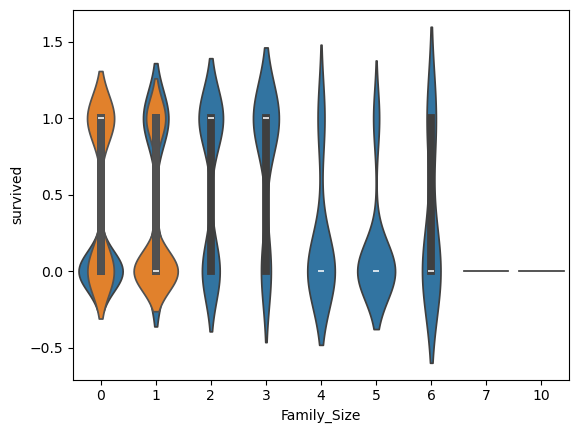

In [11]:
# Adding a column Family_Size
titanic['Family_Size'] = 0
titanic['Family_Size'] = titanic['parch']+titanic['sibsp']

# Adding a column Alone
titanic['alone'] = 0
titanic.loc[titanic.Family_Size == 0, 'alone'] = 1

# Factorplot for Family_Size
sns.violinplot(x ='Family_Size', y ='survived', data = titanic)

# Factorplot for Alone
sns.violinplot(x ='alone', y ='survived', data = titanic)

# Bar Plot for Fare (Continuous Feature) 

<Axes: xlabel='fare_range', ylabel='survived'>

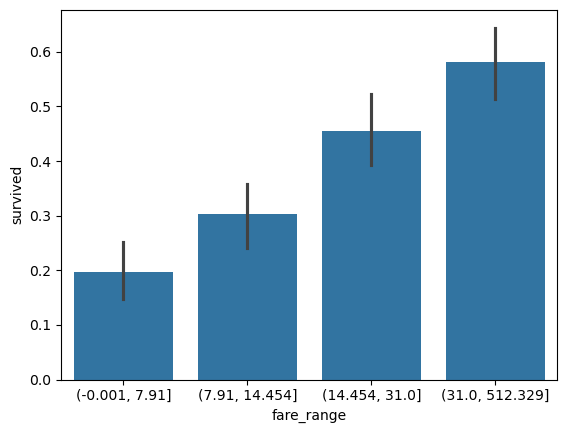

In [40]:
# Divide Fare into 4 bins
titanic['fare_range'] = pd.qcut(titanic['fare'], 4)

# Barplot - Shows approximate values based 
# on the height of bars.
sns.barplot(x ='fare_range', y ='survived', data = titanic)

# Categorical Count Plots for Embarked Feature  

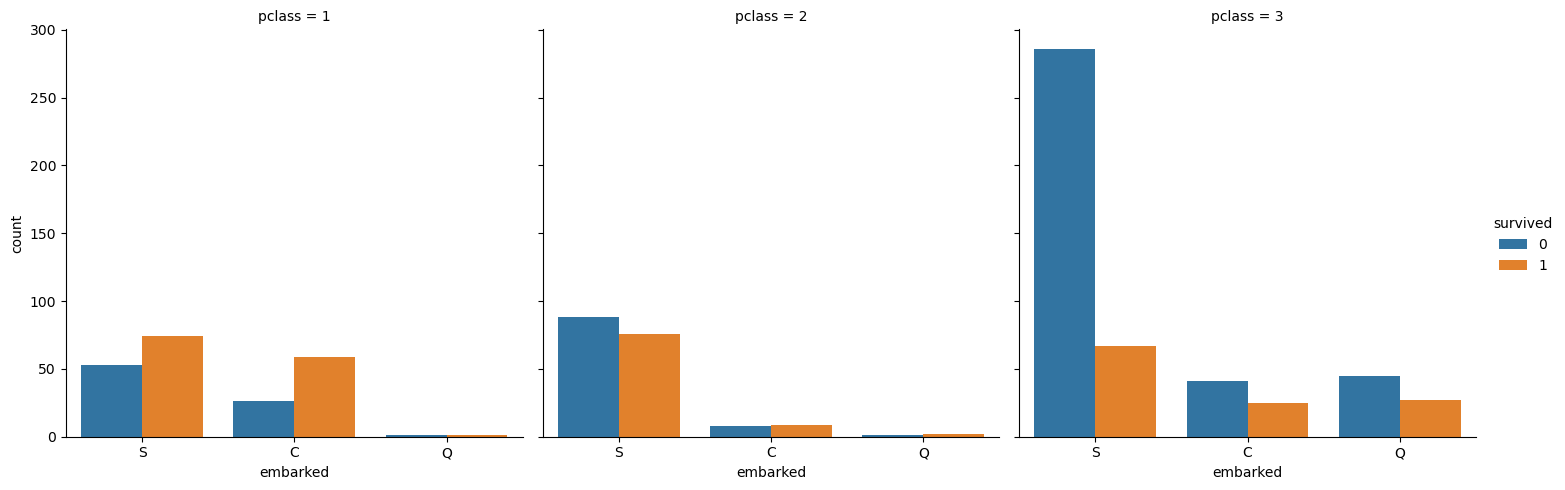

In [41]:
# Countplot
sns.catplot(x ='embarked', hue ='survived',kind ='count', col ='pclass', data = titanic)

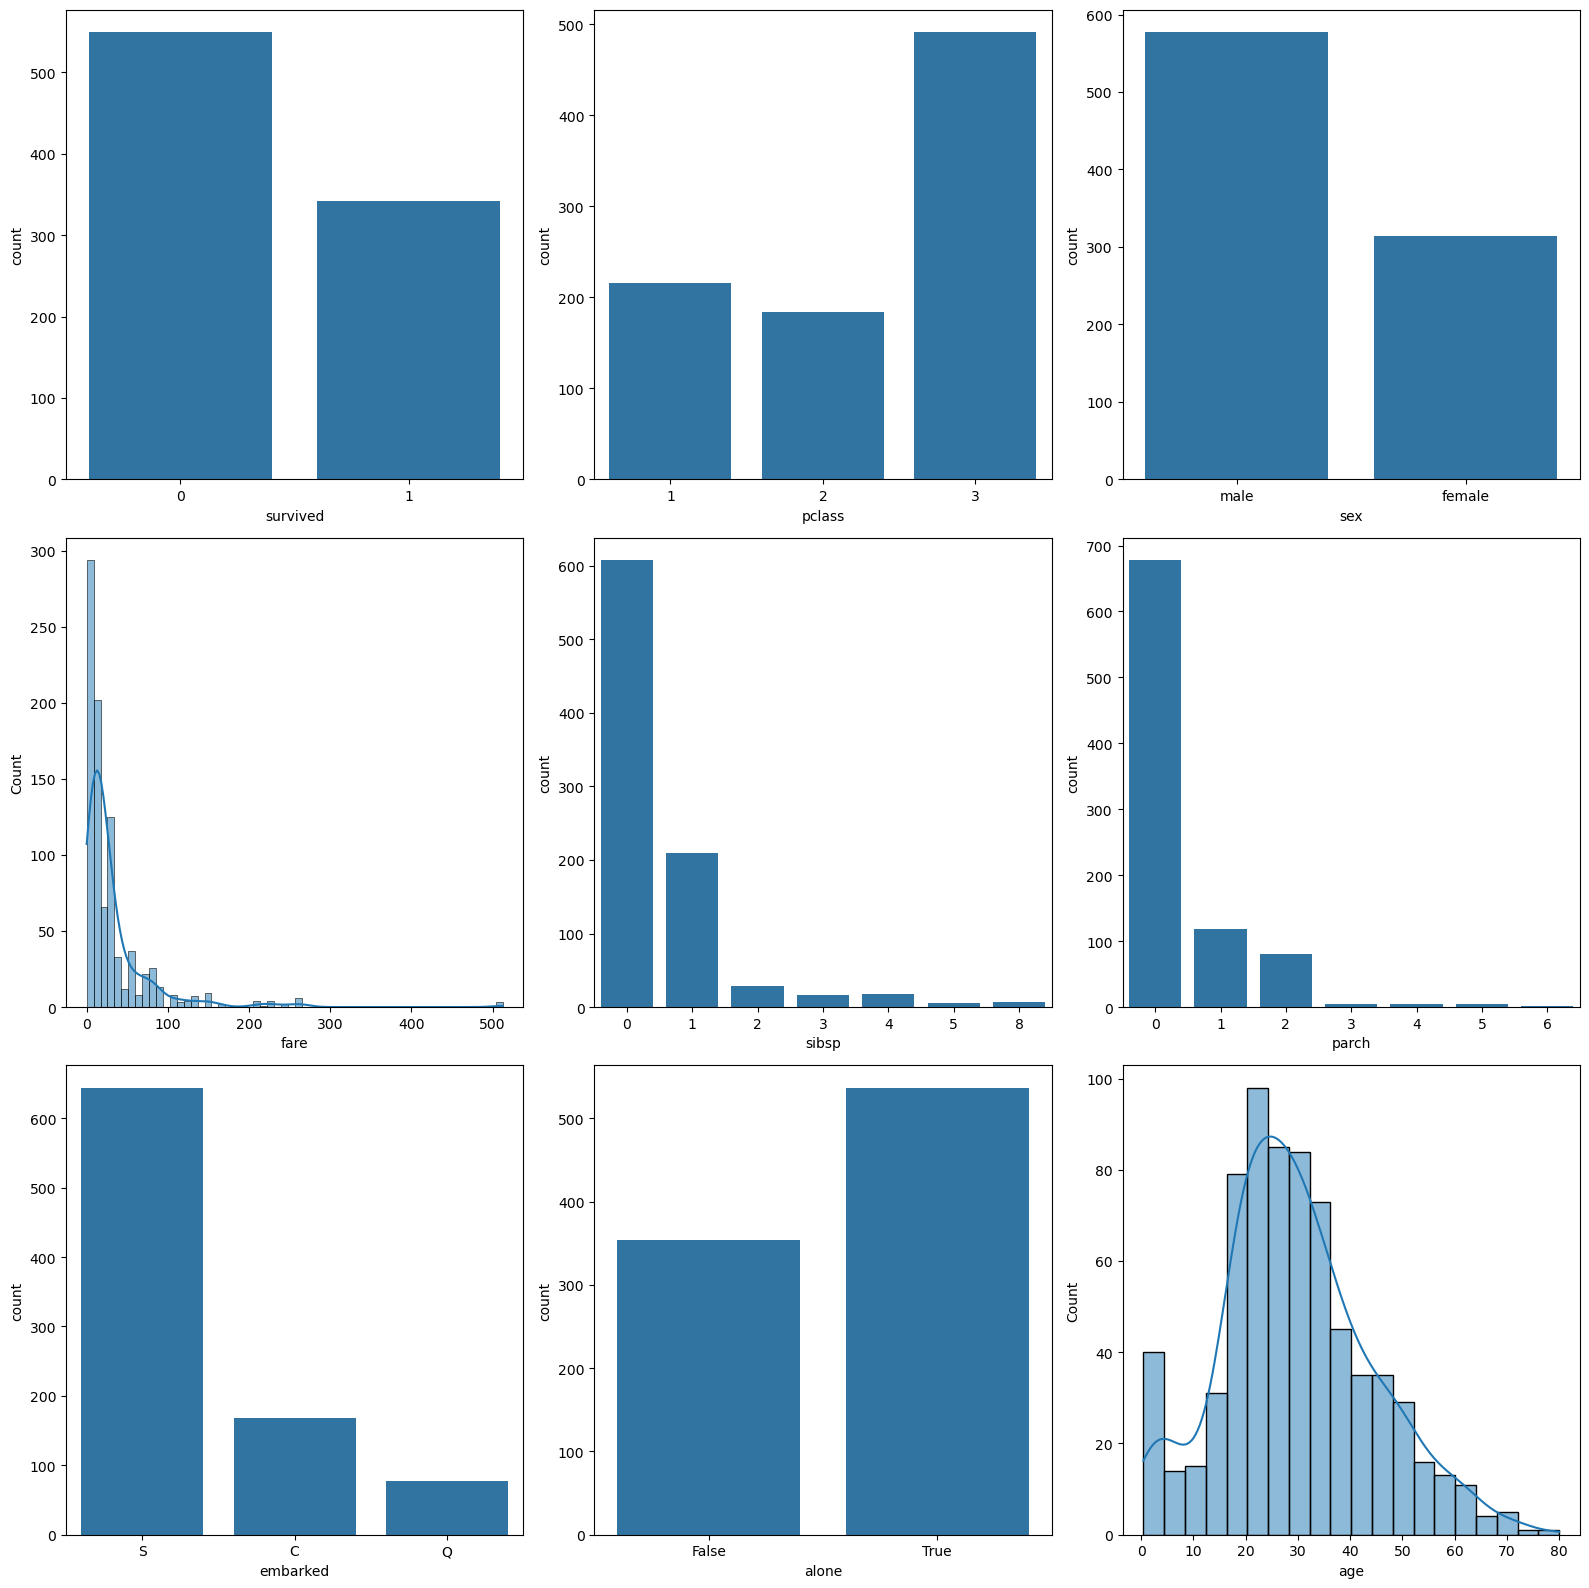

In [7]:
fig, ax = plt.subplots(3, 3, figsize = (16, 16))
sns.countplot(x='survived', data = titanic, ax = ax[0][0])
sns.countplot(x='pclass', data = titanic, ax = ax[0][1])
sns.countplot(x='sex', data = titanic, ax = ax[0][2])
sns.countplot(x='sibsp', data = titanic, ax = ax[1][1])
sns.countplot(x='parch', data = titanic, ax = ax[1][2])
sns.countplot(x='embarked', data = titanic, ax = ax[2][0])
sns.countplot(x='alone', data = titanic, ax = ax[2][1])
#sns.countplot('who', data = titanic, ax = ax[2][2])

sns.histplot(titanic, x='fare', kde=True, ax = ax[1][0])
sns.histplot(titanic, x='age', kde=True, ax = ax[2][2])

plt.tight_layout()